In [8]:
import pandas as pd

df = pd.read_csv("../data/Telco-Customer-Churn.csv")

print("Dataset size:", df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)

Dataset size: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMo

In [ ]:
# Duplicate Customer Records Check
print("Duplicate IDs:", df["customerID"].duplicated().sum())

# Charges ko numeric banao; invalid/blank entries NaN hongi
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Zero tenure customers ke blank charges ko 0 se fill karo
mask = df["tenure"].eq(0) & df["TotalCharges"].isna()
df.loc[mask, "TotalCharges"] = 0



Duplicate IDs: 0


In [13]:
print(df.isnull().sum())
print(df["Churn"].value_counts())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Churn
No     5174
Yes    1869
Name: count, dtype: int64


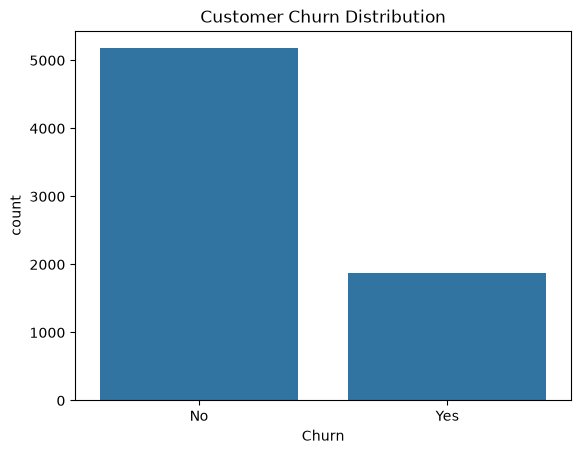

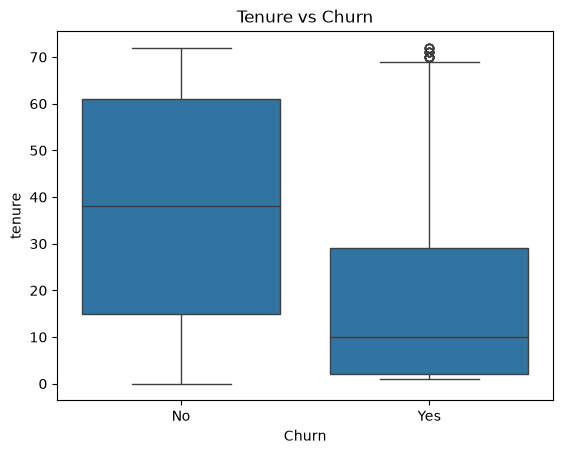

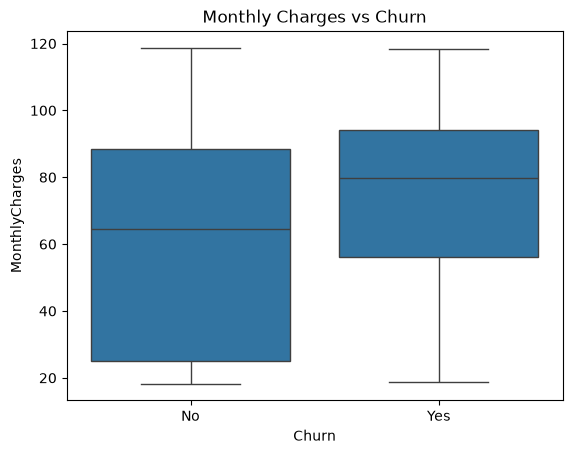

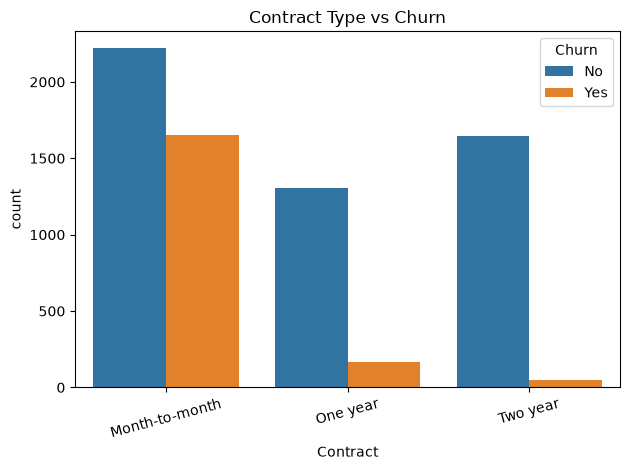

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure vs Churn")
plt.show()

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

sns.countplot(data=df, x="Contract", hue="Churn")
plt.xticks(rotation=15)
plt.title("Contract Type vs Churn")
plt.tight_layout()
plt.show()

In [15]:
import sqlite3
import pandas as pd

df = pd.read_csv("../data/Telco-Customer-Churn.csv")

with sqlite3.connect("churn.db") as conn:
    df.to_sql("customers", conn, if_exists="replace", index=False)

    result = pd.read_sql_query(
        "SELECT Contract, COUNT(*) AS customers "
        "FROM customers GROUP BY Contract",
        conn
    )

print(result)

         Contract  customers
0  Month-to-month       3875
1        One year       1473
2        Two year       1695
